<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [ISO 20022 Payments](https://github.com/Query-farm/vgi-iso20022)

Parse SWIFT MT and ISO 20022 MX payment messages into typed SQL rows, locally with no network calls.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-iso20022/blob/main/notebooks/02_compare_messages_before_status.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-iso20022/blob/main/notebooks/README.md)


## 02 · Compare message representations before interpreting payment status

During an MT-to-MX migration, a matching amount answers only one question:
do the two representations agree on that field? It does not tell us whether a
payment was accepted or settled. We will retain missing counterparts, compare
exact decimal amounts only within the same currency, then join independent
pacs.002 status observations.

**Six authored identities, no real payment data:** three comparable EUR pairs,
one currency disagreement, one MT-only payment and one MX-only payment. The
worker parses local files; this notebook does not submit or alter payments.

### Choose a display band without changing exact equality

`DISPLAY_BAND_EUR` is a decimal string from **0.00 to 1.00**, with at most two
fractional digits. Default **"0.00"** groups no nonzero differences into the band;
the experiment **"0.01"** groups one one-cent difference. This is a display
exercise, not an accounting tolerance or acceptance decision. Exact equality,
raw deltas, counterpart coverage and status observations stay unchanged.

In [1]:
DISPLAY_BAND_EUR = "0.00"  # Experiment: "0.01"

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.21":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.21"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from IPython.display import display
from vgi_notebooks import check_runtime, connect, prepare, prose, theme

check_runtime()
prepare("iso20022")
import iso20022_example as example  # noqa: E402 — download before import

example.validate_amount(DISPLAY_BAND_EUR, maximum="1.00")
fingerprint = example.verify_migration()
theme()
session = connect(globals())
con = session.connection

### Connect and discover the relevant message readers

`github-auto` downloads the platform's prebuilt **v0.4.0** release, checks its
SHA-256 and caches it. The supported-message view establishes the available
readers before we choose MT103, pacs.008 and pacs.002. No worker build, API key
or account connection is required. Standalone setup downloads only the shared
example tools and hash-verified authored fixtures.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'iso20022' (TYPE vgi,
 LOCATION 'github-auto://Query-farm/vgi-iso20022@v0.4.0');
SELECT * FROM iso20022.main.supported_messages
WHERE message_type IN ('MT103','pacs.008','pacs.002') ORDER BY message_type;

,message_type,family,reader_function,exploder_function,description
0,MT103,SWIFT MT,mt103_read,None,Single customer credit transfer (FIN MT103).
1,pacs.002,ISO 20022 MX,pacs002_read,None,Payment status report.
2,pacs.008,ISO 20022 MX,pacs008_read,None,FI-to-FI customer credit transfer.


### Inspect the MT field before comparing its typed value

Field `:32A:` contains a date, currency and amount with a comma decimal separator.
The amount scalar returns `DECIMAL(38,9)`; it does not perform currency conversion.
The raw `:71A:` charge code is a separate field. We retain it here to show why
amount agreement alone is not complete message equivalence. MT type detection
also guards the chosen reader: it reports `MT103` for these five FIN messages.

In [5]:
%%sql inspection <<
CREATE TABLE mt_inspection AS
SELECT filename,content,
 iso20022.main.iso20022_mt_type(content) AS mt_type,
 iso20022.main.iso20022_mt103_field(content,'32A') AS field_32a,
 iso20022.main.iso20022_mt103_field(content,'71A') AS charge_code,
 iso20022.main.iso20022_mt103_amount(content) AS amount
FROM read_text('fixtures/migration/mt/*.txt');
SELECT regexp_extract(filename,'(P[0-9]+)[.]txt$',1) AS payment_id,
 mt_type,field_32a,charge_code,CAST(amount AS VARCHAR) AS amount
FROM mt_inspection ORDER BY payment_id;

In [6]:
display(inspection)
assert len(inspection) == 5 and (inspection.mt_type == "MT103").all()
assert con.execute("SELECT bool_and(typeof(amount)='DECIMAL(38,9)') FROM mt_inspection").fetchone()[0]
prose("All five inputs identify as **MT103**. The scalar preserves the exact settlement amount, while raw field text retains the date/currency context. The authored SHA-256 fixture fingerprint is `" + fingerprint + "`.")

,payment_id,mt_type,field_32a,charge_code,amount
0,P1,MT103,"260101EUR1234,56",SHA,1234.560000000
1,P2,MT103,"260101EUR250,00",SHA,250.000000000
2,P3,MT103,"260101EUR80,00",SHA,80.000000000
3,P4,MT103,"260101USD75,00",SHA,75.000000000
4,P6,MT103,"260101EUR125,00",SHA,125.000000000


All five inputs identify as **MT103**. The scalar preserves the exact settlement amount, while raw field text retains the date/currency context. The authored SHA-256 fixture fingerprint is `98e3f4cca4134ef3a0ba1cb94b28aca287ed79f132ffc117b5201b8d0453b61f`.

### Separate parseability from field-rule checks

The validator returns structured errors from selected structural and field rules;
a green result does not establish full XSD or payment-network acceptance. We
validate each source representation and add one clearly labeled negative control:
changing the first MT message's charge code from `SHA` to `XXX`. That control
never enters the comparison tables. The original ten payment messages stay fixed.

In [7]:
%%sql validation <<
CREATE TABLE validation_results AS
WITH sources AS (
 SELECT 'MT ' || regexp_extract(filename,'(P[0-9]+)[.]txt$',1) AS source,content FROM read_text('fixtures/migration/mt/*.txt')
 UNION ALL
 SELECT 'MX ' || regexp_extract(filename,'(P[0-9]+)[.]xml$',1),content FROM read_text('fixtures/migration/mx/*.xml')
 UNION ALL
 SELECT 'Control: invalid charge',replace(content,':71A:SHA',':71A:XXX')
 FROM read_text('fixtures/migration/mt/P1.txt')
)
SELECT source,iso20022.main.iso20022_validate(content) AS result FROM sources;
SELECT source,result.ok AS field_checks_pass,result.errors AS errors
FROM validation_results ORDER BY source;

In [8]:
display(validation)
assert len(validation) == 11
assert con.execute("SELECT count(*)=1 AND bool_and(NOT result.ok) FROM validation_results WHERE source LIKE 'Control:%'").fetchone()[0]
assert con.execute("SELECT count(*)=10 AND bool_and(result.ok) FROM validation_results WHERE source NOT LIKE 'Control:%'").fetchone()[0]
prose("The ten original representations pass this worker's checks; the altered charge-code control fails with the returned error. The EUR/USD disagreement in P6 passes per-message checks because each individual message is internally parseable. Cross-message agreement needs a separate comparison.")

,source,field_checks_pass,errors
0,Control: invalid charge,False,"[CHRG010: :71A: charge code 'XXX' not in {OUR,..."
1,MT P1,True,[]
2,MT P2,True,[]
3,MT P3,True,[]
4,MT P4,True,[]
5,MT P6,True,[]
6,MX P1,True,[]
7,MX P2,True,[]
8,MX P3,True,[]
9,MX P5,True,[]


The ten original representations pass this worker's checks; the altered charge-code control fails with the returned error. The EUR/USD disagreement in P6 passes per-message checks because each individual message is internally parseable. Cross-message agreement needs a separate comparison.

### Audit join keys, then preserve both sides

The readers produce one row per payment in these files. We require a nonempty,
unique UETR on each side before joining; repeated UETRs would multiply rows and
need explicit handling. These authored fixtures also have matching end-to-end
IDs within each pair, which we check rather than assume.

A full outer join retains **MT-only and MX-only** identities. We compute a delta
only when both amounts and the currency agree in scope. Different currencies
remain a separate category even when their numeric amounts happen to match.

In [9]:
%%sql
CREATE TABLE mt_payments AS SELECT * FROM iso20022.main.mt103_read('fixtures/migration/mt/*.txt');
CREATE TABLE mx_payments AS SELECT * FROM iso20022.main.pacs008_read('fixtures/migration/mx/*.xml');
SELECT 'MT' AS representation,count(*) AS rows,count(DISTINCT uetr) AS unique_uetrs FROM mt_payments
UNION ALL SELECT 'MX',count(*),count(DISTINCT uetr) FROM mx_payments;

,representation,rows,unique_uetrs
0,MT,5,5
1,MX,5,5


In [10]:
assert con.execute("SELECT count(*)=5 AND count(uetr)=5 AND count(DISTINCT uetr)=5 AND bool_and(length(uetr)>0) FROM mt_payments").fetchone()[0]
assert con.execute("SELECT count(*)=5 AND count(uetr)=5 AND count(DISTINCT uetr)=5 AND bool_and(length(uetr)>0) FROM mx_payments").fetchone()[0]
assert con.execute("SELECT bool_and(m.end_to_end_id=p.end_to_end_id) FROM mt_payments m JOIN mx_payments p USING(uetr)").fetchone()[0]
assert con.execute("SELECT count(*)=5 AND bool_and(m.amount=i.amount) FROM mt_payments m JOIN mt_inspection i ON m.path=i.filename").fetchone()[0]
prose("Both readers return **five rows and five distinct UETRs**. All five MT reader amounts equal the independent scalar results. The join can therefore retain each authored identity once without an accidental many-to-many expansion.")

Both readers return **five rows and five distinct UETRs**. All five MT reader amounts equal the independent scalar results. The join can therefore retain each authored identity once without an accidental many-to-many expansion.

In [11]:
%%sql pairs <<
CREATE TABLE comparisons AS
SELECT coalesce(m.uetr,p.uetr) AS uetr,coalesce(m.end_to_end_id,p.end_to_end_id) AS payment_id,
 m.amount AS mt_amount,p.amount AS mx_amount,m.ccy AS mt_ccy,p.ccy AS mx_ccy,
 CASE WHEN m.uetr IS NULL THEN 'MX only' WHEN p.uetr IS NULL THEN 'MT only'
      WHEN m.ccy<>p.ccy THEN 'currency differs' ELSE 'comparable' END AS pair_state,
 CASE WHEN m.ccy=p.ccy THEN p.amount-m.amount END AS delta
FROM mt_payments m FULL OUTER JOIN mx_payments p USING(uetr);
SELECT payment_id,CAST(mt_amount AS VARCHAR) AS mt_amount,mt_ccy,
 CAST(mx_amount AS VARCHAR) AS mx_amount,mx_ccy,pair_state,CAST(delta AS VARCHAR) AS delta
FROM comparisons ORDER BY payment_id;

In [12]:
display(pairs)
assert con.execute("SELECT count(*)=6 AND count(DISTINCT uetr)=6 FROM comparisons").fetchone()[0]
assert con.execute("SELECT count(*)=3 AND bool_and(mt_ccy='EUR' AND mx_ccy='EUR') FROM comparisons WHERE pair_state='comparable'").fetchone()[0]
assert con.execute("SELECT count(*)=3 AND count(delta)=0 FROM comparisons WHERE pair_state<>'comparable'").fetchone()[0]
prose("Three EUR pairs permit a direct amount comparison. P4 and P5 have no counterpart, and P6 changes from EUR to USD. Their missing deltas mean **not comparable**, not a zero difference.")

,payment_id,mt_amount,mt_ccy,mx_amount,mx_ccy,pair_state,delta
0,P1,1234.560000000,EUR,1234.560000000,EUR,comparable,0.000000000
1,P2,250.000000000,EUR,250.010000000,EUR,comparable,0.010000000
2,P3,80.000000000,EUR,82.000000000,EUR,comparable,2.000000000
3,P4,75.000000000,USD,None,None,MT only,None
4,P5,None,None,75.000000000,USD,MX only,None
5,P6,125.000000000,EUR,125.000000000,USD,currency differs,None


Three EUR pairs permit a direct amount comparison. P4 and P5 have no counterpart, and P6 changes from EUR to USD. Their missing deltas mean **not comparable**, not a zero difference.

### Keep exact differences visible when grouping the display

The inclusive display band applies only to the three comparable EUR pairs. An
exact match remains its own class; a nonzero difference within the band still
appears as a signed decimal amount. No EUR/USD conversion or mixed-currency sum
is performed. The population panel retains all six identities, including the
three outside the delta calculation.

In [13]:
%%sql bands <<
CREATE TABLE banded AS
SELECT *,CASE WHEN pair_state<>'comparable' THEN pair_state
 WHEN delta=0 THEN 'exact amount'
 WHEN abs(delta)<=CAST('{{DISPLAY_BAND_EUR}}' AS DECIMAL(38,9)) THEN 'nonzero, within display band'
 ELSE 'outside display band' END AS display_group
FROM comparisons;
SELECT payment_id,CAST(delta AS VARCHAR) AS delta_eur,display_group
FROM banded ORDER BY payment_id;

,payment_id,delta_eur,display_group
0,P1,0.000000000,exact amount
1,P2,0.010000000,outside display band
2,P3,2.000000000,outside display band
3,P4,None,MT only
4,P5,None,MX only
5,P6,None,currency differs


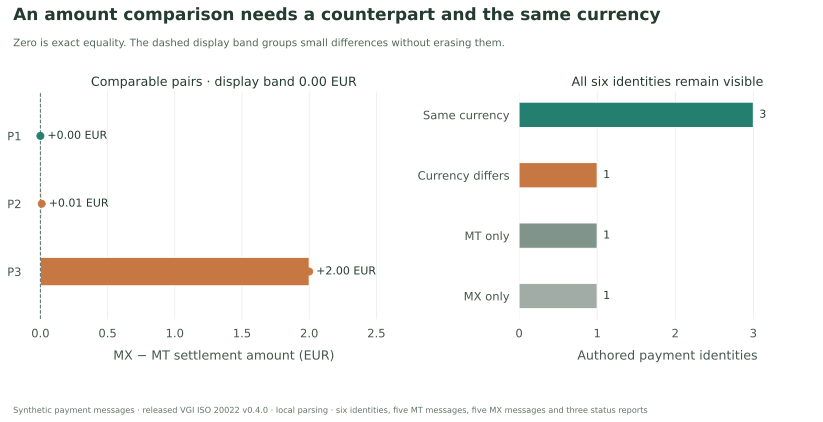

There are **1 exact amount matches**, **0 nonzero differences within the 0.00 EUR display band**, and **2 outside it**. The source deltas remain **0.00, +0.01 and +2.00 EUR** regardless of this grouping.

In [14]:
display(bands)
deltas = con.execute("SELECT payment_id,delta FROM comparisons WHERE pair_state='comparable' ORDER BY payment_id").df()
population = con.execute("SELECT pair_state,count(*) AS identities FROM comparisons GROUP BY pair_state ORDER BY CASE pair_state WHEN 'comparable' THEN 0 WHEN 'currency differs' THEN 1 WHEN 'MT only' THEN 2 ELSE 3 END").df()
assert int(population.identities.sum()) == 6 and len(deltas) == 3
example.plot_migration(deltas, population, DISPLAY_BAND_EUR)
exact, within, outside = con.execute("SELECT count(*) FILTER(WHERE display_group='exact amount'), count(*) FILTER(WHERE display_group='nonzero, within display band'),count(*) FILTER(WHERE display_group='outside display band') FROM banded").fetchone()
prose(f"There are **{exact} exact amount matches**, **{within} nonzero differences within the {DISPLAY_BAND_EUR} EUR display band**, and **{outside} outside it**. The source deltas remain **0.00, +0.01 and +2.00 EUR** regardless of this grouping.")

### Join status observations without turning absence into success

A pacs.002 report describes a different dimension from representation agreement.
The authored status set has at most one observation per original UETR; a real
history could contain several and would need an explicit temporal selection rule.
We check uniqueness before joining. `RJCT` and `ACCP` are displayed as returned
codes; an acceptance-stage observation is not proof of final settlement. A
missing report remains **no report in this fixture**, never presumed success.

In [15]:
%%sql
CREATE TABLE statuses AS SELECT * FROM iso20022.main.pacs002_read('fixtures/migration/status/*.xml');
SELECT count(*) AS reports,count(DISTINCT orig_uetr) AS distinct_payment_references FROM statuses;

,reports,distinct_payment_references
0,3,3


In [16]:
assert con.execute("SELECT count(*)=3 AND count(orig_uetr)=3 AND count(DISTINCT orig_uetr)=3 FROM statuses").fetchone()[0]
assert con.execute("SELECT count(*)=0 FROM statuses s ANTI JOIN comparisons c ON s.orig_uetr=c.uetr").fetchone()[0]

In [17]:
%%sql status_comparison <<
SELECT c.payment_id,c.pair_state,CAST(c.delta AS VARCHAR) AS delta,
 coalesce(s.tx_status,'no report in fixture') AS observed_status,s.status_reason_code
FROM comparisons c LEFT JOIN statuses s ON s.orig_uetr=c.uetr ORDER BY c.payment_id;

In [18]:
display(status_comparison)
assert len(status_comparison) == 6
assert status_comparison.loc[status_comparison.payment_id == "P1", "observed_status"].item() == "RJCT"
prose("**P1 has exactly equal amounts and a rejection report (`RJCT`, reason `AM04`).** P2 has a one-cent representation difference and an `ACCP` observation. P3 has no report here. These examples separate field agreement, observation coverage and status; none alone proves a completed transfer.")

,payment_id,pair_state,delta,observed_status,status_reason_code
0,P1,comparable,0.000000000,RJCT,AM04
1,P2,comparable,0.010000000,ACCP,None
2,P3,comparable,2.000000000,no report in fixture,None
3,P4,MT only,None,no report in fixture,None
4,P5,MX only,None,ACCP,None
5,P6,currency differs,None,no report in fixture,None


**P1 has exactly equal amounts and a rejection report (`RJCT`, reason `AM04`).** P2 has a one-cent representation difference and an `ACCP` observation. P3 has no report here. These examples separate field agreement, observation coverage and status; none alone proves a completed transfer.

### Experiment: group a one-cent difference while preserving the evidence

Run a detached copy with **"0.01"**. Predict one nonzero difference moving into
the display band and one remaining outside it. The exact-match count stays one;
all six identities, ten source messages, raw deltas and three status reports
must remain unchanged. Restore **"0.00"** for the default.

```sh
uv run --locked vgi-notebooks 02_compare_messages_before_status.ipynb \
  --parameters '{"DISPLAY_BAND_EUR":"0.01"}' --output-dir artifacts/one-cent
```

This exercise compares selected fields in synthetic messages. It does not certify
complete semantic equivalence, network acceptance or settlement. The [statement
notebook](01_reconcile_entries_not_details.ipynb) addresses a separate problem:
recovering the correct row grain before reconciling booked balances.

In [19]:
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-iso20022](https://github.com/Query-farm/vgi-iso20022)